## 1. Load Data

In [1]:
# import dataset
import pandas as pd
import numpy as np 

df = pd.read_csv("instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv.csv")

# df.head()  #samples
df.info()  #information about data
df.describe()  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


# 2. Feature Engineering 

## EDA - Exploratory Data Analysis

In [2]:
# correlation data 
df.corr(numeric_only=True)

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
completion_rate,1.000000,0.404161,0.333307,-0.953493,0.187633,0.221877,0.205793,0.315394,0.279549
avg_score_improvement,0.404161,1.000000,0.218788,-0.381354,0.128352,0.128914,0.152643,0.190054,0.198923
avg_quiz_score,0.333307,0.218788,1.000000,-0.315220,0.110648,0.115678,0.128595,0.149825,0.144783
dropout_rate,-0.953493,-0.381354,-0.315220,1.000000,-0.170536,-0.210486,-0.200598,-0.300556,-0.274475
avg_watch_time,0.187633,0.128352,0.110648,-0.170536,1.000000,0.081442,0.091414,0.117653,0.138435
assignment_submission_rate,0.221877,0.128914,0.115678,-0.210486,0.081442,1.000000,0.066776,0.070639,0.079055
forum_activity_rate,0.205793,0.152643,0.128595,-0.200598,0.091414,0.066776,1.000000,0.147115,0.126143
avg_feedback_score,0.315394,0.190054,0.149825,-0.300556,0.117653,0.070639,0.147115,1.000000,0.120092
feedback_response_rate,0.279549,0.198923,0.144783,-0.274475,0.138435,0.079055,0.126143,0.120092,1.000000


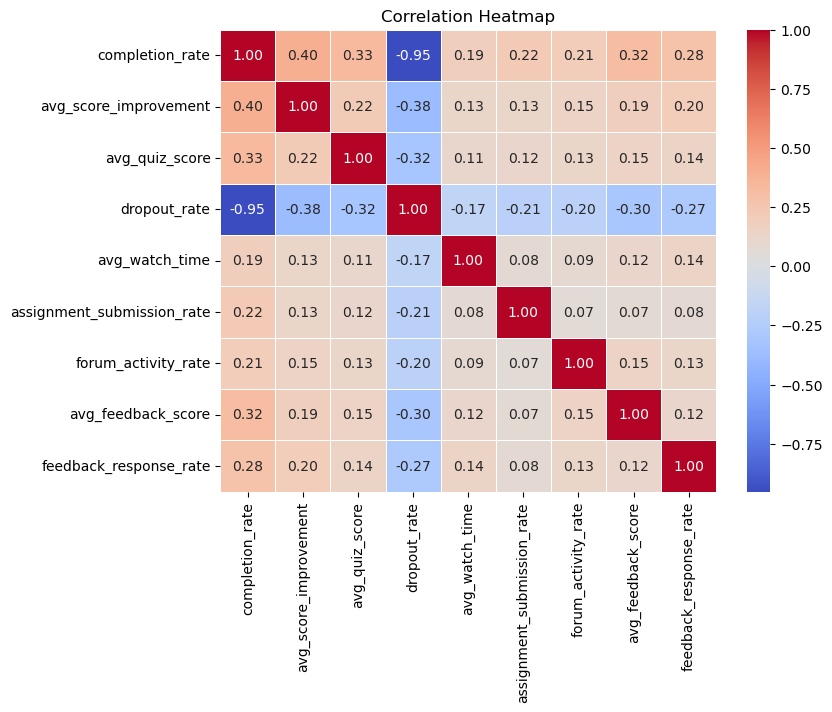

In [3]:
# Ckecking correlation with heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=.5
)

plt.title("Correlation Heatmap")
plt.show()

### Early Observation 
- **High completion rate means low dropout rate.**
- **High completion rate is linked with better score improvement.**

In [4]:
df["instructor_id"].nunique()

120

### Aggregating Batch Data
 **The Data was aggregated at the instructor level by averaging the batch-level metrics, ensuring that each instructor is represented by a single record**
#### Aggregation Function Used : Mean (Average)
#### Why it makes sense:
- It calculates the average performance of each instructor across all batches.
- It gives every instructor a single representative record for further analysis and model training.
- It avoids duplicate instructor records while preserving overall performance.

In [5]:
instructor_df = df.groupby("instructor_id").agg({
    "completion_rate":"mean",
    "avg_score_improvement":"mean",
    "avg_quiz_score":"mean",
    "avg_feedback_score":"mean",
    "assignment_submission_rate":"mean",
    "avg_watch_time":"mean",
    "forum_activity_rate":"mean",
}).reset_index()

In [6]:
instructor_df

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,avg_feedback_score,assignment_submission_rate,avg_watch_time,forum_activity_rate
0,I_001,0.543887,26.641462,78.900194,4.217743,0.726893,0.766513,0.240551
1,I_002,0.730874,30.166242,81.737198,4.343002,0.774394,0.837393,0.289610
2,I_003,0.768447,29.977813,81.590928,4.450034,0.779606,0.818441,0.296224
3,I_004,0.458328,22.912021,77.680317,4.076410,0.758317,0.793130,0.226259
4,I_005,0.859747,32.588652,85.828159,4.202516,0.876942,0.847026,0.333519
...,...,...,...,...,...,...,...,...
115,I_116,0.597106,26.029714,78.640236,4.091469,0.660695,0.761489,0.274891
116,I_117,0.691715,28.430884,80.981607,4.305839,0.814243,0.793272,0.265179
117,I_118,0.820753,32.636791,87.071798,4.641986,0.829285,0.773422,0.258419
118,I_119,0.600597,25.159349,80.735733,4.315403,0.766803,0.774830,0.227028


### Define Instructor Effectiveness
 **Weight were assigned to the selected features based on their importance and correlation. The weighted values were combined to calculate the instructor effectiveness score. dropout rate was excluded due to its strong negative correlations with all features.**

In [7]:
# measure instructor effectiveness

# define weights
w_completion = 0.30
w_improvement = 0.20
w_quiz = 0.15
w_feedback = 0.10
w_assignment = 0.10
w_watch = 0.05
w_active = 0.05

# calculating effectiveness score
instructor_df["effectiveness_score"] = (
    w_completion * instructor_df["completion_rate"] +
    w_improvement * instructor_df["avg_score_improvement"] +
    w_quiz * instructor_df["avg_quiz_score"] +
    w_feedback * instructor_df["avg_feedback_score"] +
    w_assignment * instructor_df["assignment_submission_rate"] +
    w_watch * instructor_df["avg_watch_time"] +
    w_active * instructor_df["forum_activity_rate"]
)

In [8]:
instructor_df.sample(10)

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,avg_feedback_score,assignment_submission_rate,avg_watch_time,forum_activity_rate,effectiveness_score
87,I_088,0.553806,26.691232,76.283354,4.263498,0.670313,0.695703,0.250595,17.487587
83,I_084,0.676652,27.943482,78.650497,4.248652,0.775009,0.829078,0.254300,18.145802
58,I_059,0.486194,26.075877,75.900916,4.133885,0.750942,0.742112,0.208858,17.282202
65,I_066,0.749361,29.266958,84.287491,4.286561,0.815473,0.767838,0.256909,19.282764
74,I_075,0.313393,19.763641,65.317318,3.834521,0.676044,0.655381,0.126935,14.334516
105,I_106,0.591083,27.069406,81.275611,4.113618,0.772151,0.772319,0.244224,18.321952
116,I_117,0.691715,28.430884,80.981607,4.305839,0.814243,0.793272,0.265179,18.605863
15,I_016,0.630727,27.343040,80.186398,4.077163,0.812937,0.781942,0.255759,18.226681
84,I_085,0.690698,28.408658,81.189587,4.320704,0.777968,0.813213,0.260154,18.630915
67,I_068,0.491279,26.137693,72.190390,4.097009,0.646348,0.752961,0.224039,16.726667


### Creating Effectiveness Tier
#### The effectiveness scores were categorized into *Low*, *Medium*, and *High* tiers using 'qcut' to create balanced groups.

In [9]:
# creating effectiveness tier
instructor_df["effectiveness_tier"] = pd.qcut(instructor_df["effectiveness_score"], q=3, labels=["low", "medium", "high"])

# Class Imbalance 
instructor_df["effectiveness_tier"].value_counts()

effectiveness_tier
low       40
medium    40
high      40
Name: count, dtype: int64

## Class Imbalance 

no significant class imbalance was observed. The effectiveness tier were created using quantile-based binning ('qcut'), resulting in a nearly balanced distribution of Low, Medium, and High classes.

In [10]:
instructor_df[["instructor_id", "effectiveness_score", "effectiveness_tier"]].head()

,instructor_id,effectiveness_score,effectiveness_tier
0,I_001,17.871305,medium
1,I_002,19.081180,high
2,I_003,19.043433,high
3,I_004,16.906393,low
4,I_005,20.216851,high


In [11]:
print("Max Effectiveness Score -", np.max(instructor_df["effectiveness_score"]))
print("Min Effectiveness Score -", np.min(instructor_df["effectiveness_score"]))

Max Effectiveness Score - 21.453278533813076
Min Effectiveness Score - 13.730755914961


In [12]:
instructor_df.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,avg_feedback_score,assignment_submission_rate,avg_watch_time,forum_activity_rate,effectiveness_score,effectiveness_tier
0,I_001,0.543887,26.641462,78.900194,4.217743,0.726893,0.766513,0.240551,17.871305,medium
1,I_002,0.730874,30.166242,81.737198,4.343002,0.774394,0.837393,0.289610,19.081180,high
2,I_003,0.768447,29.977813,81.590928,4.450034,0.779606,0.818441,0.296224,19.043433,high
3,I_004,0.458328,22.912021,77.680317,4.076410,0.758317,0.793130,0.226259,16.906393,low
4,I_005,0.859747,32.588652,85.828159,4.202516,0.876942,0.847026,0.333519,20.216851,high


# 3. Model Training

In [13]:
# Making Training and Testing data
from sklearn.model_selection import train_test_split

X = instructor_df.drop(columns =["instructor_id", "effectiveness_score", "effectiveness_tier"])
y = instructor_df["effectiveness_tier"]

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=40
)

In [14]:
# Random Forest Classifier Model
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(max_depth=4, random_state=40)
rfc.fit(X_train, y_train)

RandomForestClassifier(max_depth=4, random_state=40)

In [15]:
# Logistic Regression Model
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=800)
lr.fit(X_train, y_train)

LogisticRegression(max_iter=800)

In [16]:
# Decision Tree Classifier Model
from sklearn.tree import DecisionTreeClassifier

dc = DecisionTreeClassifier(max_depth=4)
dc.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4)

# Evaluation 

In [17]:
# Evaluation Metrics
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score

### Evaluation Metrics

The model was evaluated using **Accuracy, Precision and Recall**.

- **Accuracy** measures the overall percentage of correct predictions.
- **Precision** measures how many predicted labels are correct.
- **Recall** measures how many actual labels are correctly identified.

In [18]:
# Random Forest evaluation 
y_pred = rfc.predict(X_test)

print("rfc accuracy:", accuracy_score(y_test, y_pred))
print("rfc precision_score:", precision_score(y_test, y_pred, average="weighted"))
print("rfc recall_score:", recall_score(y_test, y_pred, average="weighted"))

rfc accuracy: 0.9583333333333334
rfc precision_score: 0.9629629629629629
rfc recall_score: 0.9583333333333334


In [19]:
# Logistic Regression evaluation 
y_test_pred = lr.predict(X_test)
y_train_pred = lr.predict(X_train)

print("train lr accuracy:", accuracy_score(y_train, y_train_pred))
print("test lr accuracy:", accuracy_score(y_test, y_test_pred))
print("lr precision_score:", precision_score(y_test, y_pred, average="weighted"))
print("lr recall_score:", recall_score(y_test, y_pred, average="weighted"))

train lr accuracy: 0.96875
test lr accuracy: 0.9166666666666666
lr precision_score: 0.9629629629629629
lr recall_score: 0.9583333333333334


In [20]:
# Decision Tree Classifier evaluation 
y_pred = dc.predict(X_test)

print("dc accuracy:", accuracy_score(y_test, y_pred))
print("dc precision_score:", precision_score(y_test, y_pred, average="weighted"))
print("dc recall_score:", recall_score(y_test, y_pred, average="weighted"))

dc accuracy: 0.7916666666666666
dc precision_score: 0.799404761904762
dc recall_score: 0.7916666666666666


## Precision vs Recall Trade-off

The Random Forest model achieved a Precision of **96.30%** and a Recall of **95.83%**, indicating a good balance between
making accurate predictions and correctly identifying instructor affectiveness tiers.

# 4. Interpret the Results


## Key Features Influencing Instructor Effectiveness

The most important features were:
- Completion Rate
- Average Score Improvement
- Average Quiz Score

These features were given higher importance because they directly reflect student learning and course completion.

## Results in Simple Terms

The model predicts whether an instructor is Low, Medium, or High performing based on student learning and engagement. Instructors with higher completion rates, better score improvement, and higher quiz scores are more likely to be highly effective.

## EdTech Application
These insights can help identify high-performing instructors, provide support to low-performing instructors, and improve teaching
quality by focusing on the most important performance metrics.

# 5. Mandatory Analysis Questions

### 1. Which features most influenced instructor effectiveness, and why?
* **Answer:** completion_rate, avg_score_improvement, and avg_quiz_score.
* **Reason:** They show how well students are learning and completing the course. Also, in code, I gave the weight to these features while calculating the effectiveness score.

### 2. Which variables could be misleading or confounded?
* **Answer:** Heatmap shows that "dropout_rate" has a strong negative correlation with almost every other performance metric (especially "completion_rate" at **-0.95**

### 3. How could this model fail in real-world usage?
* **Answer:** I created the effectiveness_score ourselves by manually assigning weights to features after looking at the data. The model is simply predicting labels based on our own formula rather than real-world teaching performance.

### 4. What additional data would you want to improve this analysis?
* **Answer:** The target variable (effectiveness_score) was calculated using our own defined formula and assigned weights. Instead of pre-defined correct formula which is help to calculate correct (effectiveness_score).

### 5. Should this model be used for instructor performance evaluation? Why or why not?
* **Answer:** No, because this model can be improved further so that it performs better in evaluations. After that, we can use it in the real world.